# 🌊 Side-Scan Sonar (SSS) Feature Evaluation with OK-AI SSL Models

This notebook evaluates visual representation quality on **real Side-Scan Sonar (SSS) imagery** (`test/images/*.tiff` and ground-truth masks `test/masks/*.tiff`).

It natively integrates the **OK-AI pre-trained foundation models** (`OK-AI/{objective}-vit{model_size}16-pretrain-in1k`):
- **Objectives**: **`lejepa`**, **`dino`**, **`ibot`**
- **Architectures**: **ViT-S/16** (`s`, 384-dim), **ViT-B/16** (`b`, 768-dim)
- **Revisions**: Default 300 epochs, or specific checkpoints (`ep100/student`, `ep300/teacher`, etc.)


## 1. Setup & Environment


In [1]:
import os
import glob
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Sonar-Specific Preprocessing (Pure PyTorch, Zero-Dependency)
- Extracts the single-channel acoustic backscatter intensity from 4-channel RGBA TIFFs.
- Applies percentile contrast enhancement (1st to 99th percentile) to clip extreme speckle spikes.
- Converts to normalized 3-channel PyTorch tensor via direct byte buffers (`torch.frombuffer`).


In [2]:
def load_and_preprocess_sss(image_path, target_size=(224, 224), enhance_contrast=True, device="cpu"):
    """
    Loads a Side-Scan Sonar TIFF and returns (display_pil_image, normalized_torch_tensor).
    """
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Sonar image not found: {image_path}")

    # 1. Load TIFF and convert RGBA -> 1-channel grayscale
    raw_img = Image.open(image_path)
    gray_img = raw_img.convert("L").resize(target_size, Image.Resampling.BILINEAR)

    # 2. Pure PyTorch conversion from byte buffer (no numpy bridge)
    b = bytearray(gray_img.tobytes())
    t = torch.frombuffer(b, dtype=torch.uint8).reshape(target_size[1], target_size[0]).float()

    # 3. Sonar percentile contrast stretching
    if enhance_contrast:
        p1 = torch.quantile(t, 0.01)
        p99 = torch.quantile(t, 0.99)
        if p99 > p1:
            t = torch.clamp((t - p1) / (p99 - p1) * 255.0, 0.0, 255.0)

    # 4. Build 3-channel normalized tensor [1, 3, H, W] for vision backbones
    t_3ch = (t.unsqueeze(0).repeat(3, 1, 1) / 255.0)
    mean = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)
    norm_tensor = ((t_3ch - mean) / std).unsqueeze(0).to(device)

    return gray_img, norm_tensor


def load_sonar_pair(image_path, mask_path=None, target_size=(224, 224), enhance_contrast=True, device="cpu"):
    """Loads a sonar TIFF image along with its ground-truth mask."""
    display_img, tensor_img = load_and_preprocess_sss(image_path, target_size, enhance_contrast, device)
    
    mask_arr = None
    if mask_path and os.path.exists(mask_path):
        raw_mask = Image.open(mask_path).convert("L")
        resized_mask = raw_mask.resize(target_size, Image.Resampling.NEAREST)
        b_m = bytearray(resized_mask.tobytes())
        mask_arr = torch.frombuffer(b_m, dtype=torch.uint8).reshape(target_size[1], target_size[0]).numpy()

    return display_img, tensor_img, mask_arr

print("Sonar preprocessing functions defined successfully!")


Sonar preprocessing functions defined successfully!


## 3. Test on a Sonar Sample from `test/images/`
Load a sample tile from `test/images/` and display with a copper colormap.


Loaded SSS Tile: prefix1_SC_B_RECON_5_190312220400_xtf_CH34_waterfall_stbd_31_2_0_0_0.tiff
Tensor Shape: torch.Size([1, 3, 224, 224]), Device: cuda:0


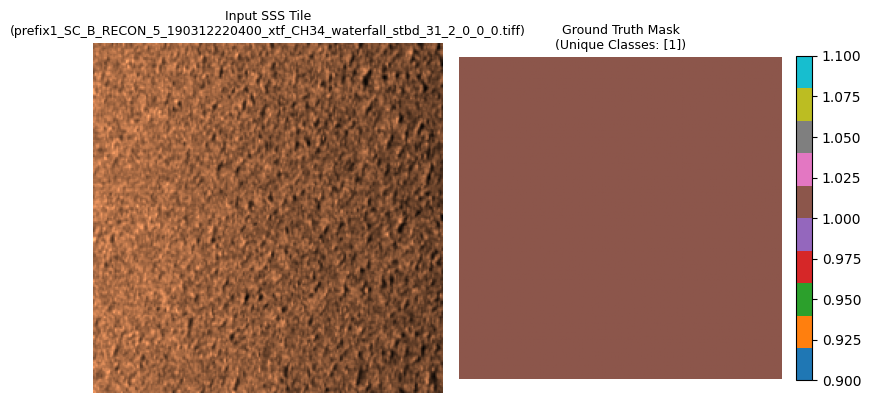

In [3]:
# Path to sample SSS image and paired ground-truth mask:
SSS_IMAGE_PATH = "test/images/prefix1_SC_B_RECON_5_190312220400_xtf_CH34_waterfall_stbd_31_2_0_0_0.tiff"
SSS_MASK_PATH = "test/masks/prefix1_SC_B_RECON_5_190312220400_xtf_CH34_waterfall_stbd_31_2_0_0_0.tiff"

sonar_img, sonar_tensor, mask_arr = load_sonar_pair(SSS_IMAGE_PATH, SSS_MASK_PATH, device=device)

print(f"Loaded SSS Tile: {os.path.basename(SSS_IMAGE_PATH)}")
print(f"Tensor Shape: {sonar_tensor.shape}, Device: {sonar_tensor.device}")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sonar_img, cmap="copper")
axes[0].set_title(f"Input SSS Tile\n({os.path.basename(SSS_IMAGE_PATH)})", fontsize=9)
axes[0].axis("off")

if mask_arr is not None:
    im = axes[1].imshow(mask_arr, cmap="tab10")
    axes[1].set_title(f"Ground Truth Mask\n(Unique Classes: {list(set(mask_arr.flatten()))})", fontsize=9)
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


## 4. Load Pretrained SSL Model (OK-AI Checkpoints)

Configure your model using the OK-AI repository naming scheme:
- `objective`: `"lejepa"`, `"dino"`, `"ibot"`
- `model_size`: `"s"` (ViT-S/16, 384-dim) or `"b"` (ViT-B/16, 768-dim)
- `pretrain_dataset`: `"in1k"`
- `use_revision`: Set `True` to load a specific checkpoint variant (e.g. `ep100/student`, `ep300/teacher`)


In [4]:
# -------------------------------------------------------------
# Configuration: Choose Objective, Size, and Revision
# -------------------------------------------------------------
objective = "dino"       # Options: "lejepa", "dino", "ibot"
model_size = "s"          # Options: "s" (ViT-S/16, 384-dim) or "b" (ViT-B/16, 768-dim)
pretrain_dataset = "in1k"

# Alternate checkpoint revision (optional):
use_revision = False       # Set True to load specific epoch & state_dict
epoch_variant = 100        # 100, 300
state_dict_of = "student"  # "student" (only option for lejepa), "teacher" or "student" (dino/ibot)

# -------------------------------------------------------------
# Model Extractor Definition
# -------------------------------------------------------------
class SSLFeatureExtractor(nn.Module):
    """Extracts global and spatial patch tokens from AutoModel or torchvision ViT."""
    def __init__(self, model, name="SSL Model", device="cpu"):
        super().__init__()
        self.model = model.to(device).eval()
        self.name = name
        self.device = device

    def forward(self, x):
        outputs = self.model(x)
        # 1. OK-AI ViTv2 output (dict with "latent" and "patch_latent")
        if isinstance(outputs, dict):
            global_feat = outputs.get("latent", outputs.get("logits", None))
            patch_feats = outputs.get("patch_latent", None)
            if patch_feats is not None:
                N = patch_feats.shape[1]
                grid = int(round(math.sqrt(N)))
                return global_feat, patch_feats, (grid, grid)
            return global_feat, None, None

        # 2. Hugging Face standard BaseModelOutput
        elif hasattr(outputs, "last_hidden_state"):
            hidden = outputs.last_hidden_state
            global_feat = hidden[:, 0]
            patch_feats = hidden[:, 1:] if hidden.shape[1] > 1 else hidden
            N = patch_feats.shape[1]
            grid = int(round(math.sqrt(N)))
            return global_feat, patch_feats, (grid, grid)

        # 3. Torchvision ViT fallback
        elif hasattr(self.model, "_process_input"):
            x_proc = self.model._process_input(x)
            n = x_proc.shape[0]
            tok = torch.cat([self.model.class_token.expand(n, -1, -1), x_proc], dim=1)
            x_enc = self.model.encoder(tok)
            return x_enc[:, 0], x_enc[:, 1:], (14, 14)

        else:
            return outputs, None, None


def load_ok_ai_model(hf_model_string, revision=None):
    """
    Downloads full repository snapshot so that configuration_vitv2.py
    and the hf_src/ directory are available on sys.path.
    Registers _keys_to_ignore_on_load_unexpected to cleanly suppress
    auxiliary pretraining projection head warnings (cva_module_proj, norm_patch, mask_token).
    """
    import os, sys, re
    from huggingface_hub import snapshot_download
    from transformers import AutoModel

    repo_dir = snapshot_download(repo_id=hf_model_string, revision=revision)
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)

    modelling_path = os.path.join(repo_dir, "modelling_vitv2.py")
    if os.path.exists(modelling_path):
        with open(modelling_path, "r") as f:
            code = f.read()
        patterns = "[r'cva_module_proj', r'norm_patch', r'mask_token']"
        if "_keys_to_ignore_on_load_unexpected" in code:
            code = re.sub(r"_keys_to_ignore_on_load_unexpected = .*", "_keys_to_ignore_on_load_unexpected = " + patterns, code)
        else:
            rep = "config_class = ViTv2Config" + chr(10) + "    _keys_to_ignore_on_load_unexpected = " + patterns
            code = code.replace("config_class = ViTv2Config", rep)
        with open(modelling_path, "w") as f:
            f.write(code)

    return AutoModel.from_pretrained(repo_dir, trust_remote_code=True)


# -------------------------------------------------------------
# Load Model & Initialize Extractor
# -------------------------------------------------------------
hf_model_string = f"OK-AI/{objective}-vit{model_size}16-pretrain-{pretrain_dataset}"
print(f"Target Model: {hf_model_string}")
revision = f"ep{epoch_variant}/{state_dict_of}" if use_revision else None
if revision:
    print(f"Using revision: {revision}")

try:
    print(f"Downloading/loading snapshot for '{hf_model_string}'...")
    raw_model = load_ok_ai_model(hf_model_string, revision=revision)
    print(f"✅ Successfully loaded {hf_model_string} from Hugging Face!")
except Exception as e:
    print(f"⚠️ Could not load from Hugging Face ({e}).")
    print("Falling back to local cached torchvision ViT-B/16...")
    import torchvision.models as models
    raw_model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

extractor = SSLFeatureExtractor(raw_model, name=hf_model_string, device=device)
print(f"Feature Extractor ready on {device}!")


Target Model: OK-AI/dino-vits16-pretrain-in1k
Downloading/loading snapshot for 'OK-AI/dino-vits16-pretrain-in1k'...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 37 files:   0%|          | 0/37 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/150 [00:00<?, ?it/s]

✅ Successfully loaded OK-AI/dino-vits16-pretrain-in1k from Hugging Face!
Feature Extractor ready on cuda!


## 5. Unsupervised PCA Semantic Segmentation

Computes top-3 PCA on spatial patch tokens $\mathbf{z}_i \in \mathbb{R}^D$ and normalizes to RGB channels.


Global Embedding Shape: torch.Size([1, 384])
Patch Tokens Shape:     torch.Size([1, 196, 384]) (Grid: (14, 14))


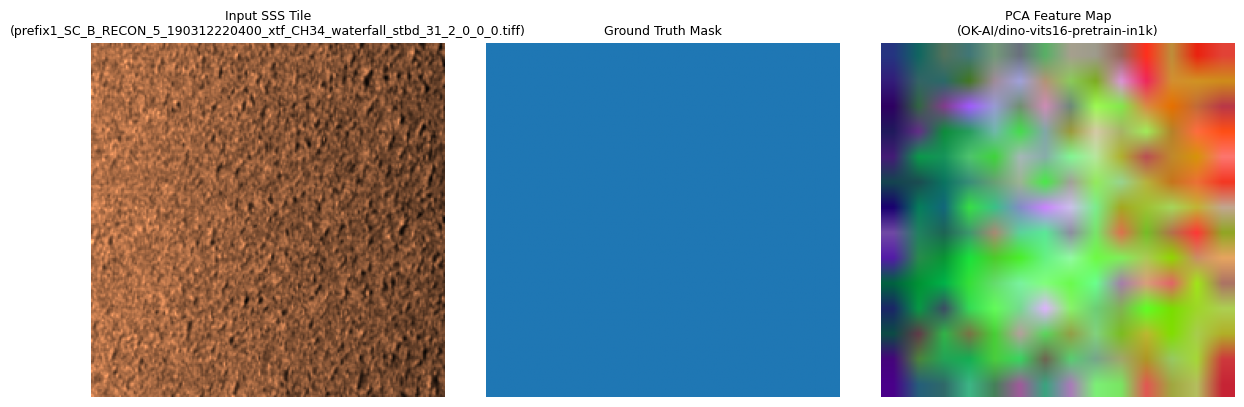

In [5]:
def compute_pca_map(patch_feats, grid_size, output_size=(224, 224)):
    """Computes top-3 PCA on patch tokens using pure PyTorch operations."""
    feats = patch_feats[0].float() # [N, D]
    centered = feats - feats.mean(dim=0, keepdim=True)
    
    # Low-rank PCA via SVD
    U, S, V = torch.pca_lowrank(centered, q=3, center=False)
    proj = torch.matmul(centered, V[:, :3]) # [N, 3]
    
    # Percentile normalization (1st to 99th percentile)
    p1 = torch.quantile(proj, 0.01, dim=0, keepdim=True)
    p99 = torch.quantile(proj, 0.99, dim=0, keepdim=True)
    norm_proj = torch.clamp((proj - p1) / (p99 - p1 + 1e-8), 0.0, 1.0)
    
    H_g, W_g = grid_size
    grid = norm_proj.reshape(1, H_g, W_g, 3).permute(0, 3, 1, 2)
    
    # Bilinear upsample to target resolution
    upsampled = F.interpolate(grid, size=output_size, mode="bilinear", align_corners=False)
    pca_img = upsampled[0].permute(1, 2, 0).cpu().clamp(0.0, 1.0).numpy()
    return pca_img

# Extract features and generate PCA segmentation map
with torch.no_grad():
    g_feat, p_feat, grid_sz = extractor(sonar_tensor)

print(f"Global Embedding Shape: {g_feat.shape}")
print(f"Patch Tokens Shape:     {p_feat.shape} (Grid: {grid_sz})")

pca_map = compute_pca_map(p_feat, grid_sz, output_size=(224, 224))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sonar_img, cmap="copper")
axes[0].set_title(f"Input SSS Tile\n({os.path.basename(SSS_IMAGE_PATH)})", fontsize=9)
axes[0].axis("off")

if mask_arr is not None:
    axes[1].imshow(mask_arr, cmap="tab10")
    axes[1].set_title("Ground Truth Mask", fontsize=9)
    axes[1].axis("off")

axes[2].imshow(pca_map)
axes[2].set_title(f"PCA Feature Map\n({extractor.name})", fontsize=9)
axes[2].axis("off")

plt.tight_layout()
plt.show()


## 6. Quantitative Benchmark: Feature-to-Ground-Truth Alignment

Evaluates how well the extracted patch features separate the ground-truth acoustic classes:
1. Downsamples the ground-truth mask to the patch grid ($14 \times 14$).
2. Computes the normalized class centroids $\mathbf{\mu}_c$ in feature space.
3. Measures pairwise **Inter-Class Cosine Distance** ($1 - \cos(\mathbf{\mu}_a, \mathbf{\mu}_b)$).
4. Evaluates **Nearest-Centroid Accuracy**: tests whether raw features are linearly separable across the acoustic classes without fine-tuning.


In [6]:
def evaluate_feature_mask_alignment(patch_feats, grid_size, mask_224):
    feats = patch_feats[0].detach() # [N_patches, D]
    norm_feats = F.normalize(feats, p=2, dim=1) # [N, D]
    H_grid, W_grid = grid_size
    N, D = norm_feats.shape
    
    # Pure PyTorch mask downsampling (avoids PIL data type limits)
    mask_tensor = torch.from_numpy(mask_224).float().unsqueeze(0).unsqueeze(0)
    downsampled = F.interpolate(mask_tensor, size=(H_grid, W_grid), mode="nearest").squeeze().long()
    mask_grid = downsampled.flatten().cpu().numpy()
    
    unique_classes = sorted(list(set(mask_grid)))
    if len(unique_classes) < 2:
        print("Tile contains only 1 class. Skipping multi-class alignment.")
        return

    centroids = {}
    for c in unique_classes:
        mask_c = (mask_grid == c)
        c_patches = norm_feats[mask_c]
        centroids[c] = F.normalize(c_patches.mean(dim=0, keepdim=True), p=2, dim=1)

    print("=" * 60)
    print(" 📊 FEATURE-TO-MASK ALIGNMENT REPORT")
    print("=" * 60)
    print(f"Classes present in tile: {unique_classes}")
    
    dist_matrix = np.zeros((len(unique_classes), len(unique_classes)))
    for i, c1 in enumerate(unique_classes):
        for j, c2 in enumerate(unique_classes):
            sim = torch.dot(centroids[c1].squeeze(), centroids[c2].squeeze()).item()
            dist = 1.0 - sim
            dist_matrix[i, j] = dist
            if j > i:
                print(f"• Separation (Class {c1} vs Class {c2}): {dist:.4f} (Cosine Distance)")

    # Nearest-Centroid Accuracy
    all_centroids = torch.cat([centroids[c] for c in unique_classes], dim=0) # [C, D]
    logits = torch.matmul(norm_feats, all_centroids.T) # [N, C]
    preds = np.array([unique_classes[i] for i in logits.argmax(dim=1).cpu().numpy()])
    acc = 100.0 * np.mean(preds == mask_grid)

    print("-" * 60)
    print(f"• Zero-Shot Nearest-Centroid Accuracy: {acc:.2f}% (Chance: {100.0 / len(unique_classes):.1f}%)")
    print("=" * 60)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(mask_grid.reshape(H_grid, W_grid), cmap="tab10")
    axes[0].set_title(f"Downsampled Mask ({H_grid}x{W_grid})")
    axes[0].axis("off")

    im = axes[1].imshow(dist_matrix, cmap="YlOrRd", vmin=0.0, vmax=1.0)
    axes[1].set_xticks(range(len(unique_classes)))
    axes[1].set_yticks(range(len(unique_classes)))
    axes[1].set_xticklabels([f"C{c}" for c in unique_classes])
    axes[1].set_yticklabels([f"C{c}" for c in unique_classes])
    axes[1].set_title("Inter-Class Cosine Distance")
    for i in range(len(unique_classes)):
        for j in range(len(unique_classes)):
            axes[1].text(j, i, f"{dist_matrix[i, j]:.2f}", ha="center", va="center", color="black" if dist_matrix[i, j] < 0.6 else "white", fontweight="bold")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

if mask_arr is not None:
    evaluate_feature_mask_alignment(p_feat, grid_sz, mask_arr)


Tile contains only 1 class. Skipping multi-class alignment.


## 7. Comparative Benchmark: LeJEPA vs. DINO vs. iBOT on Sonar
Compare the 3 self-supervised pretraining objectives on the exact same Side-Scan Sonar tile!


In [7]:
objectives = ["lejepa", "dino", "ibot"]
pca_results = {}

for obj in objectives:
    hf_id = f"OK-AI/{obj}-vit{model_size}16-pretrain-{pretrain_dataset}"
    try:
        m = AutoModel.from_pretrained(hf_id)
        ext = SSLFeatureExtractor(m, name=obj, device=device)
        with torch.no_grad():
            _, pf, gsz = ext(sonar_tensor)
        pca_results[obj] = compute_pca_map(pf, gsz, output_size=(224, 224))
    except Exception as e:
        print(f"Skipping {obj} ({e})")

if pca_results:
    cols = 2 + len(pca_results)
    fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 3.5))
    
    axes[0].imshow(sonar_img, cmap="copper")
    axes[0].set_title("Input SSS Tile")
    axes[0].axis("off")

    if mask_arr is not None:
        axes[1].imshow(mask_arr, cmap="tab10")
        axes[1].set_title("Ground Truth Mask")
        axes[1].axis("off")

    for i, (name, pca_img) in enumerate(pca_results.items()):
        axes[2 + i].imshow(pca_img)
        axes[2 + i].set_title(f"{name.upper()} PCA")
        axes[2 + i].axis("off")

    plt.tight_layout()
    plt.show()


Skipping lejepa (The repository OK-AI/lejepa-vits16-pretrain-in1k contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/OK-AI/lejepa-vits16-pretrain-in1k .
 You can inspect the repository content at https://hf.co/OK-AI/lejepa-vits16-pretrain-in1k.
Please pass the argument `trust_remote_code=True` to allow custom code to be run.)
Skipping dino (The repository OK-AI/dino-vits16-pretrain-in1k contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/OK-AI/dino-vits16-pretrain-in1k .
 You can inspect the repository content at https://hf.co/OK-AI/dino-vits16-pretrain-in1k.
Please pass the argument `trust_remote_code=True` to allow custom code to be run.)
Skipping ibot (The repository OK-AI/ibot-vits16-pretrain-in1k contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/OK-AI

## 8. Interactive Explorer: Test Any of the 1,800 Tiles
Change `TILE_INDEX` below to evaluate any image across `test/images/`!


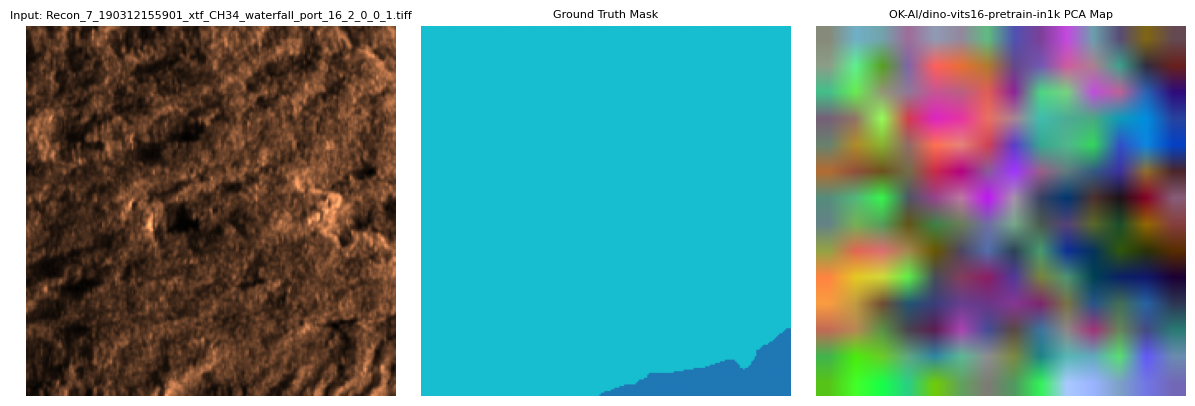

 📊 FEATURE-TO-MASK ALIGNMENT REPORT
Classes present in tile: [0, 2]
• Separation (Class 0 vs Class 2): 0.3679 (Cosine Distance)
------------------------------------------------------------
• Zero-Shot Nearest-Centroid Accuracy: 98.98% (Chance: 50.0%)


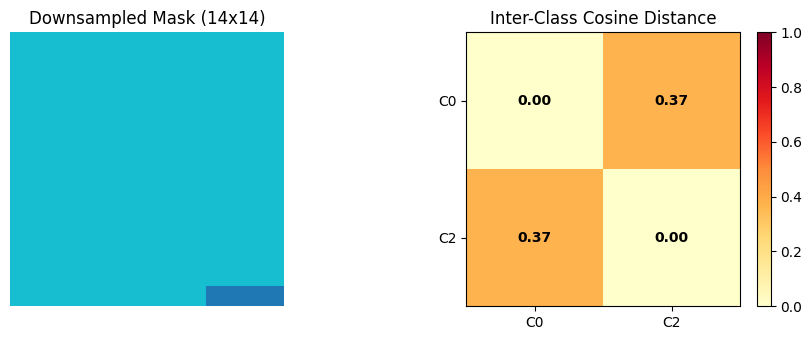

In [13]:
DATA_DIR = "test"
image_files = sorted(glob.glob(os.path.join(DATA_DIR, "images", "*.tiff")))
mask_files = sorted(glob.glob(os.path.join(DATA_DIR, "masks", "*.tiff")))

# Choose any index from 0 to 1799:
TILE_INDEX = 19

img_path = image_files[TILE_INDEX]
m_path = mask_files[TILE_INDEX]

s_img, s_tensor, m_arr = load_sonar_pair(img_path, m_path, device=device)

with torch.no_grad():
    _, p_f, g_sz = extractor(s_tensor)

pca_view = compute_pca_map(p_f, g_sz, output_size=(224, 224))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(s_img, cmap="copper")
axes[0].set_title(f"Input: {os.path.basename(img_path)}", fontsize=8)
axes[0].axis("off")

if m_arr is not None:
    axes[1].imshow(m_arr, cmap="tab10")
    axes[1].set_title(f"Ground Truth Mask", fontsize=8)
    axes[1].axis("off")

axes[2].imshow(pca_view)
axes[2].set_title(f"{extractor.name} PCA Map", fontsize=8)
axes[2].axis("off")

plt.tight_layout()
plt.show()

if m_arr is not None:
    evaluate_feature_mask_alignment(p_f, g_sz, m_arr)
